# Chapitre 13 - Exercices 13.1 à 13.5

Ce notebook traite les cinq premiers exercices du chapitre 13, centrés sur
l'intégration de données et la lecture de l'état dérivé :

- **13.1** : combien de clés divergent par jour avec la double écriture ? (calcul et
  simulation) ;
- **13.2** : quand l'ordre total sature, et ce que coûte la causalité explicite (calcul) ;
- **13.3** : bascule progressive ou bascule d'un coup : combien de lectures fausses ?
  (calcul et simulation) ;
- **13.4** : rejouer deux ans d'historique dans un nouveau consommateur (dimensionnement) ;
- **13.5** : taille optimale d'un cache de requêtes fréquentes sous une loi de Zipf
  (calcul et mini-lab).

In [1]:
import math
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import dataflow as dfl
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 4)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

## Exercice 13.1 : combien de clés divergent par jour avec la double écriture ?

**Énoncé.** Une application écrit elle-même chaque mise à jour dans sa base **et** dans
son index de recherche (double écriture). Chaque envoi subit un délai réseau égal à une
constante plus une variable exponentielle de moyenne $j = 20$ ms, indépendante pour
chaque message. Chaque système garde la dernière valeur reçue.

1. Deux clients modifient la même clé, le second $g$ millisecondes après le premier.
   Montrer que, dans un système donné, la première écriture arrive après la seconde avec
   probabilité $p(g) = \frac12 e^{-g/j}$, et que base et index divergent avec probabilité
   $2p(1-p)$.
2. Chaque jour, 50 000 paires d'écritures concurrentes sur une même clé se produisent,
   avec un écart $g$ uniforme entre 0 et 50 ms. Combien de clés divergent par jour ?
3. Vérifier par simulation.
4. Pourquoi un horodatage attaché par le client à chaque écriture (on garde la plus
   récente) ne règle-t-il pas complètement le problème ?

**Rappels.** Sans journal unique, chaque système applique les écritures dans l'ordre où
il les reçoit ; un journal ordonné décide une fois pour toutes (cours 1, section 2 ;
section *Reasoning about dataflows*).

**Solution.**

*1.* Notons $D_A, D_B$ les délais exponentiels (la constante s'annule). A arrive après B
si $D_A > g + D_B$, soit $X = D_A - D_B > g$. La différence de deux exponentielles
indépendantes de même paramètre suit une loi de Laplace de densité $\frac{1}{2j}e^{-|x|/j}$,
donc pour $g \ge 0$ : $P(X > g) = \int_g^\infty \frac{1}{2j} e^{-x/j}\,dx = \frac12 e^{-g/j}$.
Les deux systèmes sont indépendants : ils divergent si l'un garde A et l'autre B, soit
$p(1-p) + (1-p)p = 2p(1-p)$.

*2.* $2p - 2p^2 = e^{-g/j} - \frac12 e^{-2g/j}$. En moyenne sur $g$ uniforme dans $[0, G]$ :

$$\overline{P} = \frac{j}{G}\left(1 - e^{-G/j}\right) - \frac{j}{4G}\left(1 - e^{-2G/j}\right)
= 0{,}4 \times 0{,}918 - 0{,}1 \times 0{,}993 \approx 0{,}268.$$

Plus d'un quart des paires concurrentes divergent : environ **13 400 clés par jour**,
définitivement incohérentes entre la base et l'index.

*4.* Avec un horodatage client et la règle « la plus récente gagne », les deux systèmes
convergent vers la **même** valeur (ils appliquent la même règle aux mêmes données). Mais
cette valeur dépend d'horloges non synchronisées (chapitre 9) : si l'horloge
du client A avance de 30 ms, son écriture « gagne » alors qu'elle est antérieure, et
l'écriture de B est **perdue silencieusement** dans les deux systèmes. On remplace une
divergence par une perte de mise à jour. Le journal unique donne au contraire un ordre
que tous les consommateurs partagent.

**Vérification** : formule, intégrale numérique et simulation (`dfl.dual_write_divergence`).

formule 0.2678 ; intégrale numérique 0.2679 ; simulation 0.2682
clés divergentes par jour : 13 392


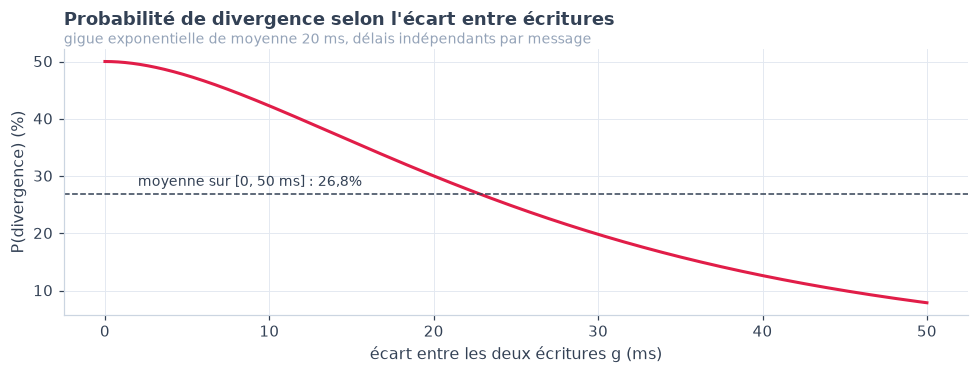

In [2]:
G, j = 50.0, 20.0
moy = (j / G) * (1 - math.exp(-G / j)) - (j / (4 * G)) * (1 - math.exp(-2 * G / j))
gs = np.linspace(0, G, 2001)
integ = np.mean([dfl.dual_write_divergence_formula(g, j) for g in gs])
rng = np.random.default_rng(0)
sim = np.mean([dfl.dual_write_divergence(g, j, n_trials=200, seed=i) for i, g in enumerate(rng.uniform(0, G, 2500))])
print(f"formule {moy:.4f} ; intégrale numérique {integ:.4f} ; simulation {sim:.4f}")
print(f"clés divergentes par jour : {fmt(50_000 * moy)}")
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(gs, [dfl.dual_write_divergence_formula(g, j) * 100 for g in gs], color=ROSE)
ax.axhline(moy * 100, color=SLATE, ls="--", lw=1)
ax.text(2, moy * 100 + 1.5, f"moyenne sur [0, 50 ms] : {moy:.1%}".replace(".", ","), color=SLATE, fontsize=9)
ax.set_xlabel("écart entre les deux écritures g (ms)"); ax.set_ylabel("P(divergence) (%)")
ax.set_title("Probabilité de divergence selon l'écart entre écritures")
subtitle(ax, "gigue exponentielle de moyenne 20 ms, délais indépendants par message")
plt.tight_layout(); plt.show()

Formule, intégrale et simulation concordent à 27 % : la double écriture produit chaque
jour plus de dix mille incohérences permanentes dans ce scénario modeste.

> **À retenir.** Pour des délais exponentiels, la divergence vaut $2p(1-p)$ avec
> $p = \frac12 e^{-g/j}$ : elle n'est négligeable que si les écritures concurrentes sont
> espacées de plusieurs fois la gigue. Un horodatage client fait converger mais perd des
> écritures ; seul un ordre unique (journal) règle le problème.

## Exercice 13.2 : quand l'ordre total sature, et ce que coûte la causalité explicite

**Énoncé.** Un journal à leader unique ordonne tous les événements d'une plateforme.

1. Le leader supporte au plus 200 000 événements/s. La charge actuelle est de 120 000
   événements/s et croît de 60 % par an. Dans combien de temps faut-il
   sharder le journal ?
2. Après sharding, les amitiés et les messages sont dans des journaux différents.
   Le service de notifications les reçoit avec des délais indépendants, exponentiels de
   moyenne 1 s. Un utilisateur retire un ami puis, 0,5 s plus tard, envoie un message
   désobligeant. Quelle est la probabilité que l'ex-ami soit notifié ?
3. Correctif : le message porte la version de la liste d'amis vue par l'expéditeur, et
   le service attend de l'avoir appliquée. Calculer l'attente moyenne ajoutée.
4. Pourquoi les horodatages de Lamport ne suffisent-ils pas, seuls, à éviter la fuite ?

**Rappels.** L'ordre total équivaut au consensus et passe par un nœud ; sans lui, les
dépendances causales entre journaux se perdent (cours 1, sections 4 et 5 ; sections
*The limits of total ordering* et *Ordering events to capture causality*).

**Solution.**

*1.* $120\,000 \times 1{,}6^t = 200\,000 \iff t = \ln(5/3) / \ln 1{,}6 \approx 1{,}09$ an :
un peu plus d'un an, en supposant une croissance régulière (les pics saisonniers
avanceront l'échéance).

*2.* Avec $X = D_f - D_m$ (délai du retrait moins délai du message), la fuite a lieu si le
retrait arrive après le message : $X > g$, de probabilité $\frac12 e^{-g/j} =
\frac12 e^{-0{,}5} \approx 30{,}3$ %.

*3.* L'attente vaut $(X - g)^+$. Pour la loi de Laplace,
$E[(X-g)^+] = \int_g^\infty (x-g)\frac{1}{2j}e^{-x/j}dx = \frac{j}{2}e^{-g/j} \approx 0{,}303$ s.
Remarquable : l'attente moyenne est numériquement égale à la probabilité de fuite (en
unités de $j$), car quand il faut attendre, l'attente résiduelle est exponentielle de
moyenne $j$ (absence de mémoire).

*4.* Un horodatage de Lamport donne un ordre total cohérent avec la causalité, mais le
service ne sait pas, à la réception du message (horodatage 12, disons), s'il existe
encore un événement d'horodatage plus petit en route : il devrait attendre d'avoir reçu
quelque chose de plus récent de **chaque** journal, ce qui revient à reconstruire un ordre
total, avec un coût de métadonnées. La référence explicite dit **exactement** quoi
attendre.

**Vérification** (`dfl.unfriend_experiment`).

In [3]:
t_sat = math.log(200 / 120) / math.log(1.6)
r = dfl.unfriend_experiment([0.5], jitter=1.0, n_trials=200_000, seed=1)
pd.DataFrame({"grandeur": ["saturation du leader (années)", "P(fuite) sans correctif", "attente moyenne avec correctif (s)",
                           "attente p99 avec correctif (s)"],
              "calcul": [f"{t_sat:.3f}", f"{0.5 * math.exp(-0.5):.4f}", f"{0.5 * math.exp(-0.5):.4f}", "-"],
              "simulation": ["-", f"{r['leak'][0]:.4f}", f"{r['wait_mean'][0]:.4f}", f"{r['wait_p99'][0]:.2f}"]})

,grandeur,calcul,simulation
0,saturation du leader (années),1.087,-
1,P(fuite) sans correctif,0.3033,0.3033
2,attente moyenne avec correctif (s),0.3033,0.3030
3,attente p99 avec correctif (s),-,3.41


La simulation retrouve 30 % de fuites et 0,30 s d'attente moyenne. Le p99 de l'attente
(près de 3,4 s) rappelle que le correctif ajoute parfois une latence notable : c'est le
prix de la causalité.

> **À retenir.** Un leader unique finit toujours par saturer ; après découpage, une
> dépendance causale entre journaux fuit avec probabilité $\frac12 e^{-g/j}$. La rendre
> explicite coûte en moyenne $\frac{j}{2}e^{-g/j}$ d'attente, avec une queue de l'ordre de
> quelques $j$.

## Exercice 13.3 : bascule progressive ou bascule d'un coup ?

**Énoncé.** On migre un service de lecture vers une nouvelle vue dérivée. La nouvelle
vue a un bogue qui rend fausses 2 % de ses réponses. Le service reçoit 1 million de
lectures par jour, uniformément. La supervision déclenche une alerte quand elle a vu
**200 réponses fausses** de la nouvelle vue ; il faut ensuite **2 heures** pour décider et
revenir à l'ancienne vue (toujours entretenue).

1. Bascule d'un coup (100 % du trafic) : au bout de combien de temps l'alerte se
   déclenche-t-elle, et combien de lectures fausses ont été servies au total ?
2. Bascule progressive : 1 % du trafic pendant la première journée. Mêmes questions.
3. Commenter le compromis.
4. Vérifier par simulation (lectures fausses comme processus de Poisson), sur 2 000
   répétitions.

**Rappels.** Deux vues dérivées du même journal peuvent coexister ; le retour en arrière
est immédiat tant que l'ancienne est entretenue (cours 1, section 6 ; section
*Reprocessing data for application evolution*).

**Solution.** Débit de réponses fausses : $\lambda f b$ par jour, avec $\lambda = 10^6$,
$b = 0{,}02$ et $f$ la fraction routée.

*1.* $f = 1$ : 20 000 réponses fausses par jour, soit 833 par heure. L'alerte se déclenche
après $200 / 833 \approx 0{,}24$ h (14 min environ) ; pendant les 2 h de décision, 1 667
réponses fausses de plus : **environ 1 870** au total.

*2.* $f = 0{,}01$ : 200 réponses fausses par jour. L'alerte se déclenche en moyenne au bout
d'**une journée** ; les 2 h suivantes ajoutent $200 \times 2/24 \approx 17$ réponses :
**environ 217** au total, près de neuf fois moins.

*3.* La bascule progressive **détecte plus lentement** (un jour contre un quart d'heure)
mais **fait moins de dégâts** : le seuil de détection (200) est atteint de toute façon, et
c'est le délai de réaction qui fait la différence, multiplié par la fraction exposée.
Avec une détection par **taux d'erreur** comparé à l'ancienne vue (canari), on peut
détecter plus vite à faible trafic, au prix de faux positifs.

**Vérification par simulation** : on tire le temps d'arrivée de la 200e erreur (loi
Gamma), puis les erreurs pendant le délai de réaction (loi de Poisson).

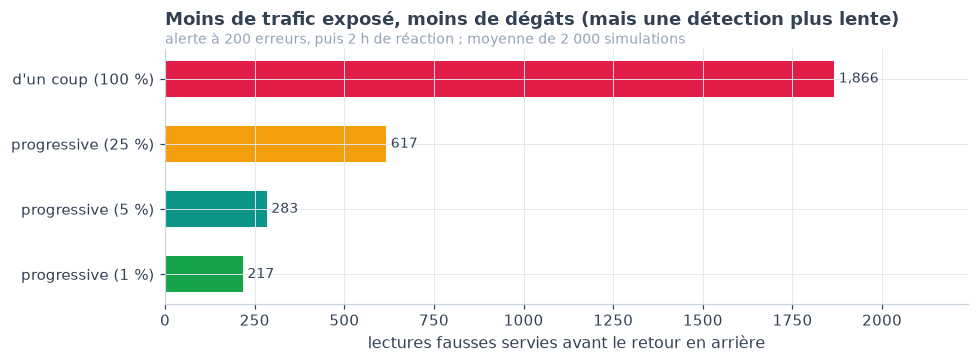

,bascule,alerte après (h),lectures fausses (simulation),lectures fausses (calcul)
0,d'un coup (100 %),0.2405,1866.2510,1866.6667
1,progressive (25 %),0.9613,616.8060,616.6667
2,progressive (5 %),4.8078,283.3655,283.3333
3,progressive (1 %),24.0511,216.6220,216.6667


In [4]:
rng = np.random.default_rng(3)
lam, b, seuil, reaction = 1e6, 0.02, 200, 2 / 24
rows = []
for f, nom in [(1.0, "d'un coup (100 %)"), (0.25, "progressive (25 %)"), (0.05, "progressive (5 %)"), (0.01, "progressive (1 %)")]:
    rate = lam * f * b                                   # erreurs par jour
    t_alert = rng.gamma(seuil, 1 / rate, 2000)
    extra = rng.poisson(rate * reaction, 2000)
    rows.append({"bascule": nom, "alerte après (h)": t_alert.mean() * 24, "lectures fausses (simulation)": (seuil + extra).mean(),
                 "lectures fausses (calcul)": seuil + rate * reaction})
R = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.barh(R["bascule"][::-1], R["lectures fausses (simulation)"][::-1], color=[GREEN, TEAL, AMBER, ROSE], height=0.55)
annotate_bars(ax, "{:,.0f}")
ax.set_xlim(0, R["lectures fausses (simulation)"].max() * 1.2)
ax.set_xlabel("lectures fausses servies avant le retour en arrière")
ax.set_title("Moins de trafic exposé, moins de dégâts (mais une détection plus lente)")
subtitle(ax, "alerte à 200 erreurs, puis 2 h de réaction ; moyenne de 2 000 simulations")
plt.tight_layout(); plt.show()
R

La simulation confirme : environ 1 870 lectures fausses pour la bascule d'un coup, 217
pour la bascule à 1 %, au prix d'une alerte 100 fois plus tardive (24 h contre 14 min).

> **À retenir.** Avec une alerte à seuil fixe, les dégâts valent « seuil + fraction
> exposée × débit × délai de réaction » : la bascule progressive réduit le second terme,
> et la coexistence des vues rend le retour en arrière instantané.

## Exercice 13.4 : rejouer deux ans d'historique dans un nouveau consommateur

**Énoncé.** Un journal conserve deux ans d'événements (5 000 événements/s en moyenne,
200 octets chacun, répliqués 3 fois). On déploie une nouvelle version d'un traitement qui
doit **tout rejouer** (architecture kappa) avant de remplacer l'ancienne. Le journal a 32
shards ; une instance du traitement lit 20 000 événements/s par shard.

1. Quel volume de stockage le journal occupe-t-il ?
2. Combien de temps faut-il pour rattraper le présent, sachant que les événements
   continuent d'arriver pendant le rejeu ?
3. Même question si la charge courante a des pics à 15 000 événements/s.
4. Quelle capacité de lecture minimale permet de rattraper en moins de 24 h ?
5. Si le traitement n'a besoin que du **dernier état par clé** (50 millions de clés), que
   gagne-t-on avec un journal compacté ?

**Rappels.** Le rejeu exige un journal rejouable, une sémantique exactement une fois et
des fenêtres par temps d'événement ; le retard se résorbe à la vitesse $c - r$ (cours 1,
section 7 ; cours 2, section 2 ; section *Unifying batch and stream processing*).

**Solution.**

*1.* $N = 5\,000 \times 86\,400 \times 730 \approx 3{,}15 \cdot 10^{11}$ événements, soit
$63$ To, et **189 To** avec la réplication.

*2.* Capacité $c = 32 \times 20\,000 = 640\,000$ événements/s ; arrivées $r = 5\,000$/s.
Le retard initial $N$ se résorbe en $N / (c - r) \approx 3{,}15 \cdot 10^{11} / 635\,000
\approx 4{,}96 \cdot 10^5$ s, soit **5,7 jours**.

*3.* Même avec $r = 15\,000$ en permanence : $N / 625\,000 \approx 5{,}8$ jours. Le débit
courant est négligeable devant la capacité de rejeu : c'est le volume historique qui
domine.

*4.* $N / (c - r) \le 86\,400 \iff c \ge N/86\,400 + r \approx 3{,}65$ millions d'événements/s,
soit 183 shards lus en parallèle à 20 000/s (ou des instances plus rapides). Le
parallélisme du rejeu est borné par le nombre de shards : c'est un argument pour en
prévoir largement.

*5.* $50 \cdot 10^6 \times 200$ octets = **10 Go** au lieu de 63 To, et un rejeu en
$5 \cdot 10^7 / 635\,000 \approx 80$ s. La compaction ne garde que le dernier état par clé
(chapitre 12) : parfait pour reconstruire une vue de l'état courant, inutile si
le nouveau traitement a besoin de l'historique (agrégats par fenêtre de temps).

**Vérification** : modèle fluide heure par heure (retard = retard + arrivées - capacité),
avec une charge journalière qui monte à 15 000/s six heures par jour.

événements : 3.154e+11 ; stockage : 63 To (189 To répliqué)


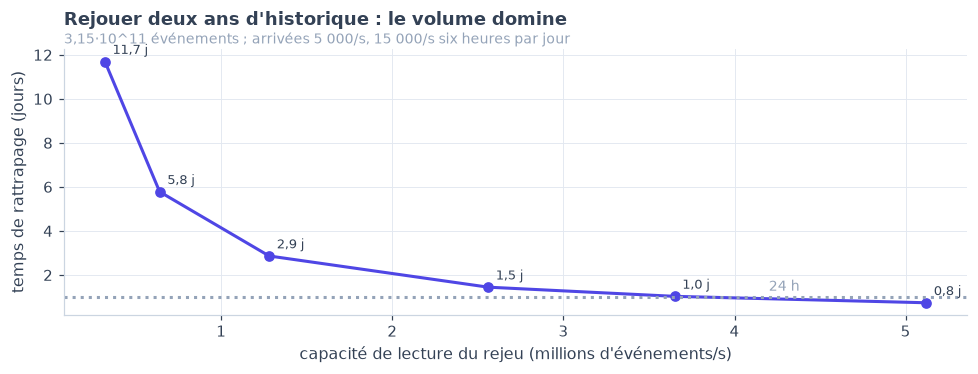

In [5]:
N = 5000 * 86400 * 730
print(f"événements : {N:.3e} ; stockage : {N * 200 / 1e12:.0f} To ({N * 200 * 3 / 1e12:.0f} To répliqué)")
hours = np.arange(24 * 10)
arrivals = np.where(hours % 24 < 18, 5000, 15000) * 3600.0
def catch_up(c):
    backlog, t = float(N), 0
    while backlog > 0:
        backlog = max(0.0, backlog + arrivals[t % len(arrivals)] - c * 3600)
        t += 1
    return t
caps = np.array([0.32, 0.64, 1.28, 2.56, 3.65, 5.12]) * 1e6
res = [catch_up(c) for c in caps]
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(caps / 1e6, np.array(res) / 24, "o-", color=INDIGO)
ax.axhline(1, color=GRAY, ls=":"); ax.text(4.2, 1.3, "24 h", color=GRAY, fontsize=9)
for c, h in zip(caps, res):
    ax.annotate(f"{h / 24:.1f} j".replace(".", ","), (c / 1e6, h / 24), (5, 5), textcoords="offset points", fontsize=8.5)
ax.set_xlabel("capacité de lecture du rejeu (millions d'événements/s)"); ax.set_ylabel("temps de rattrapage (jours)")
ax.set_title("Rejouer deux ans d'historique : le volume domine")
subtitle(ax, "3,15·10^11 événements ; arrivées 5 000/s, 15 000/s six heures par jour")
plt.tight_layout(); plt.show()

Le modèle fluide donne 5,8 jours à 640 000 événements/s (les pics quotidiens n'ajoutent
que quelques heures) et environ un jour à 3,65 millions : le calcul à la main
suffit.

> **À retenir.** Temps de rattrapage = historique / (capacité - débit courant). Pour un
> historique long, le débit courant compte peu : il faut du parallélisme de lecture (donc
> des shards) ou un journal compacté quand l'état courant suffit.

## Exercice 13.5 : taille optimale d'un cache de requêtes fréquentes

**Énoncé.** On reprend le modèle du cours 3 : une recherche par l'index coûte $r_0 = 600$
opérations, une réponse en cache 1 ; chaque document écrit coûte $w_0 = 40$ opérations
d'indexation plus 2 opérations par requête en cache (on vérifie s'il y correspond). Les
$N = 5\,000$ requêtes distinctes ont une popularité de Zipf d'exposant 1 : la $k$-ième
requête a une probabilité $\propto 1/k$. On fait $R$ lectures par écriture.

1. Exprimer le taux de succès $H(K)$ d'un cache des $K$ requêtes les plus fréquentes.
2. Écrire le coût par écriture $C(K) = w_0 + 2K + R\,[(1 - H(K))\,r_0 + H(K)]$ et montrer
   que l'optimum vérifie approximativement $K^* \approx \frac{R(r_0 - 1)}{2\,H_N}$, où $H_N$
   est le $N$-ième nombre harmonique.
3. Application pour $R = 1, 10, 100$ ; vérifier numériquement et par une mesure sur un
   flux de requêtes simulé.
4. Lien avec l'approche hybride des timelines (chapitre 2).

**Rappels.** Caches et vues matérialisées déplacent la frontière entre chemin
d'écriture et chemin de lecture (cours 3, section 2 ; section *Materialized views and
caching*).

**Solution.**

*1.* $H(K) = \sum_{k \le K} \frac1k / \sum_{k \le N} \frac1k = H_K / H_N \approx
\frac{\ln K + 0{,}577}{H_N}$, avec $H_{5000} \approx 9{,}09$.

*2.* $C(K) = w_0 + 2K + R\,r_0 - R(r_0 - 1)H(K)$. En traitant $K$ comme continu,
$H'(K) \approx 1/(K H_N)$, et $C'(K) = 2 - \frac{R(r_0 - 1)}{K H_N} = 0$ donne
$K^* = \frac{R(r_0-1)}{2H_N}$. Interprétation : on ajoute la requête de rang $K$ tant que
l'économie à la lecture ($R(r_0 - 1)$ fois sa probabilité $\frac{1}{K H_N}$) dépasse le
coût à l'écriture (2).

*3.* $K^* \approx 33$ pour $R = 1$, $329$ pour $R = 10$, $3\,290$ pour $R = 100$ (borné
en pratique par $N$). L'optimum croît **linéairement** avec le rapport lectures/écritures.

*4.* C'est le même raisonnement marginal que pour décider quels comptes diffuser à
l'écriture : on précalcule (on matérialise) ce qui est lu assez souvent pour rentabiliser
le coût d'écriture. Les célébrités, lues par énormément de monde mais coûteuses à
diffuser, sont traitées à la lecture.

**Vérification** : optimum numérique de la formule exacte, puis mesure sur 200 000
requêtes tirées selon la loi de Zipf (le taux de succès est mesuré, pas calculé).

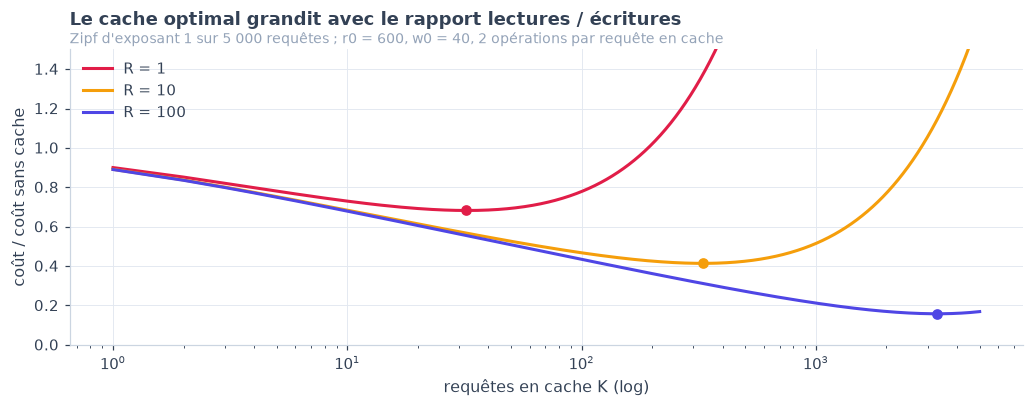

,R,K* (formule approchée),K* (optimum exact),K* (taux mesuré),gain vs sans cache
0,1,32.9320,32,33,0.3177
1,10,329.3196,329,330,0.5862
2,100,3293.1960,3293,3421,0.8422


In [6]:
Nq, r0, w0 = 5000, 600, 40
Hn = np.cumsum(1 / np.arange(1, Nq + 1))
Ks = np.arange(1, Nq + 1)
qs = dfl.zipf_queries(200_000, Nq, a=1.0, seed=4)
freq = np.sort(np.bincount(qs, minlength=Nq))[::-1]
hit_mes = np.cumsum(freq) / freq.sum()
rows = []
fig, ax = plt.subplots(figsize=(9.5, 3.8))
for R_, col in [(1, ROSE), (10, AMBER), (100, INDIGO)]:
    C = w0 + 2 * Ks + R_ * ((1 - Hn / Hn[-1]) * r0 + Hn / Hn[-1])
    Cm = w0 + 2 * Ks + R_ * ((1 - hit_mes) * r0 + hit_mes)
    k_formule = R_ * (r0 - 1) / (2 * Hn[-1])
    rows.append({"R": R_, "K* (formule approchée)": k_formule, "K* (optimum exact)": Ks[np.argmin(C)],
                 "K* (taux mesuré)": Ks[np.argmin(Cm)], "gain vs sans cache": 1 - C.min() / (w0 + R_ * r0)})
    ax.plot(Ks, C / (w0 + R_ * r0), color=col, label=f"R = {R_}")
    ax.scatter([Ks[np.argmin(C)]], [C.min() / (w0 + R_ * r0)], color=col, zorder=3)
ax.set_xscale("log"); ax.set_ylim(0, 1.5)
ax.set_xlabel("requêtes en cache K (log)"); ax.set_ylabel("coût / coût sans cache")
ax.set_title("Le cache optimal grandit avec le rapport lectures / écritures")
subtitle(ax, "Zipf d'exposant 1 sur 5 000 requêtes ; r0 = 600, w0 = 40, 2 opérations par requête en cache")
ax.legend(); plt.tight_layout(); plt.show()
pd.DataFrame(rows)

La formule approchée tombe très près de l'optimum exact, et le taux de succès mesuré sur
un flux simulé donne le même ordre de grandeur (l'écart vient du bruit d'échantillonnage
sur les requêtes rares, qui aplatit la queue de la distribution). Le gain atteint 32 % pour
une lecture par écriture, 59 % pour 10 et 84 % pour 100.

> **À retenir.** Sous une loi de Zipf, le taux de succès d'un cache croît comme $\ln K$,
> et la taille optimale vaut environ $R(r_0 - 1)/(2H_N)$ : proportionnelle au rapport
> lectures/écritures. Matérialiser se décide par un calcul marginal, comme le fan-out des
> timelines.